<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/harmonik_matris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

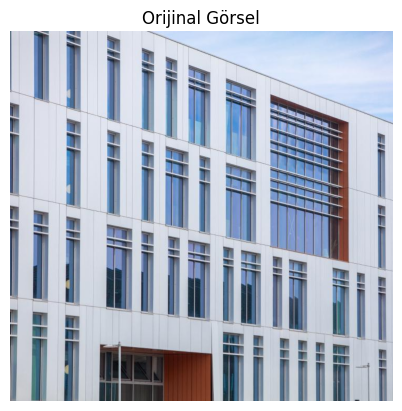

In [2]:
resim = cv2.imread("image9.jpeg")

plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Görsel")
plt.axis("off")
plt.show()

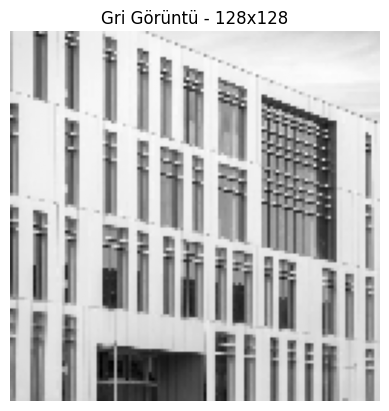

In [3]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

gri = cv2.resize(gri, (128, 128))

plt.imshow(gri, cmap="gray")
plt.title("Gri Görüntü - 128x128")
plt.axis("off")
plt.show()

In [4]:
def dft2_hesapla(goruntu):

    if goruntu.ndim != 2:
        raise ValueError("Görüntü gri olmalıdır!")

    M, N = goruntu.shape

    x = np.arange(M)
    y = np.arange(N)

    W_satir = np.exp(
        -2j * np.pi * np.outer(x, x) / M
    )

    W_sutun = np.exp(
        -2j * np.pi * np.outer(y, y) / N
    )

    harmonik = W_satir @ goruntu @ W_sutun.T

    return harmonik

In [5]:
harmonik = dft2_hesapla(gri)

print("Görüntü boyutu:", gri.shape)
print("Harmonik matris boyutu:", harmonik.shape)

print("\nHarmonik matrisin ilk 5x5 bölümü:")
print(harmonik[:5, :5])

Görüntü boyutu: (128, 128)
Harmonik matris boyutu: (128, 128)

Harmonik matrisin ilk 5x5 bölümü:
[[ 2.79070700e+06     +0.j          8.13522390e+04 -28505.86030891j
   3.69851275e+04 -37352.13041229j  2.35861798e+04 +40550.87039028j
  -8.23345187e+03 +49804.97353148j]
 [ 1.01380954e+04-124237.96374862j -7.59723730e+03+108252.06871768j
  -2.75061613e+04 -18800.6330483j   5.57136248e+03 -33775.03405481j
  -4.69462475e+03  +1780.3315701j ]
 [-2.10151547e+04-109412.59545847j  3.16884766e+04 +67629.42670647j
   4.47168128e+04  -1553.90012182j  4.77812749e+02 +27386.15332957j
   1.10929150e+04 +19291.05830162j]
 [-3.61611541e+04-108827.08948081j -5.59517872e+03 +43771.09688944j
   3.89205621e+04  -8254.0001733j  -8.48325021e+03 -11285.07817853j
  -3.27347911e+04 -11175.37477142j]
 [ 8.37333638e+03-103725.36189409j -3.65379201e+04 +25516.73762675j
   2.58917478e+04  -3168.81592133j  1.33611515e+04 -10452.09349391j
   7.77842275e+02 -16235.67960812j]]


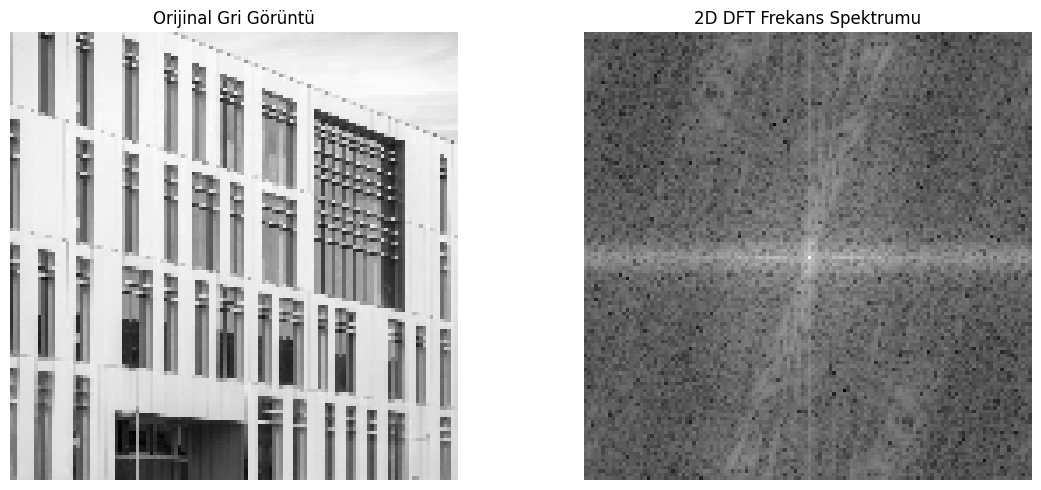

In [6]:
kaydirilmis = np.fft.fftshift(harmonik)

spektrum = np.log1p(np.abs(kaydirilmis))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gri, cmap="gray")
plt.title("Orijinal Gri Görüntü")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(spektrum, cmap="gray")
plt.title("2D DFT Frekans Spektrumu")
plt.axis("off")

plt.tight_layout()
plt.savefig("odev37_dft_sonuc.png", dpi=200)
plt.show()

In [7]:
hazir_dft = np.fft.fft2(gri)

dogru_mu = np.allclose(
    harmonik,
    hazir_dft,
    atol=1e-6
)

print("DFT fonksiyonu doğru mu?", dogru_mu)

print(
    "Maksimum fark:",
    np.max(np.abs(harmonik - hazir_dft))
)

DFT fonksiyonu doğru mu? True
Maksimum fark: 1.2218863644630356e-08
